# Actividad 3. K-Means (20 puntos)

**Evaluación Parcial N°3: PCA, K-Means y ensambles**

Se aplica K-Means sobre los datos de **entrenamiento escalados** (sin la etiqueta `precio_alto`), con `random_state=42`, para K = 3 y K = 4. Se comparan con el coeficiente Silhouette y se grafican sobre PC1 y PC2.

1. K-Means con K = 3 y random_state=42.
2. K-Means con K = 4 y coeficiente Silhouette de ambas soluciones.
3. Dos gráficos de dispersión sobre PC1 y PC2, coloreados según los grupos de cada K.

## 1. Librerías, configuración y datos

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Reproducibilidad
SEMILLA = 42

# Rutas: carpeta del proyecto en local o carpeta de trabajo en Colab
RUTA_PROYECTO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
NOMBRE_ARCHIVO = "entrenamiento_escalado.csv"
rutas_posibles = [RUTA_PROYECTO / "data" / "processed" / NOMBRE_ARCHIVO, Path.cwd() / NOMBRE_ARCHIVO, Path("/content") / NOMBRE_ARCHIVO]
RUTA_DATOS = next((ruta for ruta in rutas_posibles if ruta.exists()), rutas_posibles[0])
RUTA_IMAGENES = RUTA_PROYECTO / "images"
RUTA_IMAGENES.mkdir(parents=True, exist_ok=True)

# Colores y estilo de los gráficos (mismos del notebook principal)
COLOR_PRINCIPAL = "#2a78d6"
COLOR_SECUNDARIO = "#eb6834"
COLOR_TERCIARIO = "#1baf7a"
COLOR_NEUTRO = "#8a8984"
PALETA = [COLOR_PRINCIPAL, COLOR_SECUNDARIO, COLOR_TERCIARIO, "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

sns.set_theme(style="whitegrid", palette=PALETA)
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 100, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#ebeae6", "lines.linewidth": 2,
})
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

def guardar_figura(nombre_archivo):
    # Guarda la figura activa en images/
    plt.savefig(RUTA_IMAGENES / f"{nombre_archivo}.png", dpi=120, bbox_inches="tight")

train = pd.read_csv(RUTA_DATOS)
X_train_escalado = train.drop(columns="precio_alto")   # K-Means no usa la etiqueta
y_train = train["precio_alto"]                          # solo para interpretar los grupos
print(f"Datos: {X_train_escalado.shape[0]:,} viviendas x {X_train_escalado.shape[1]} variables")
X_train_escalado.head()

Datos: 1,755 viviendas x 8 variables


,Overall Qual,Gr Liv Area,Garage Cars,Year Built,Full Bath,Total Bsmt SF,Year Remod/Add,Fireplaces
0,-0.066701,0.284576,0.317374,0.904585,0.787531,-0.259822,0.666643,0.629412
1,1.360859,0.029680,1.624866,0.806163,0.787531,0.858012,0.523913,0.629412
2,-0.780481,0.088181,0.317374,-2.179305,0.787531,-0.931953,0.856949,0.629412
3,-0.066701,-0.582487,-0.990118,0.084402,-1.038251,-0.879517,-0.522774,-0.922018
4,0.647079,4.170690,1.624866,-2.966681,2.613314,1.022469,0.856949,0.629412


## 2. K-Means con K = 3 y K = 4

K-Means se ajusta con las **8 variables escaladas** (no con PC1 y PC2). Las dos componentes del PCA (Actividad 2) se usan solo para dibujar los grupos en un plano. Se fija `n_init=10` para que el resultado sea reproducible.

In [2]:
resultados = {}
for k in (3, 4):
    modelo = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X_train_escalado)
    resultados[k] = {
        "modelo": modelo,
        "etiquetas": modelo.labels_,
        "silhouette": silhouette_score(X_train_escalado, modelo.labels_),
    }

comparacion = pd.DataFrame({
    "K": [3, 4],
    "silhouette": [resultados[k]["silhouette"] for k in (3, 4)],
    "inercia": [resultados[k]["modelo"].inertia_ for k in (3, 4)],
}).set_index("K")
comparacion.round(3)

,silhouette,inercia
K,,
3,0.216,7968.169
4,0.209,7088.584


## 3. Gráficos de dispersión sobre PC1 y PC2

Se usa el mismo PCA de dos componentes de la Actividad 2 (ajustado solo con entrenamiento). Las cruces negras son los centroides proyectados al plano.

Varianza explicada: PC1 49.59%, PC2 14.05%, acumulada 63.64%


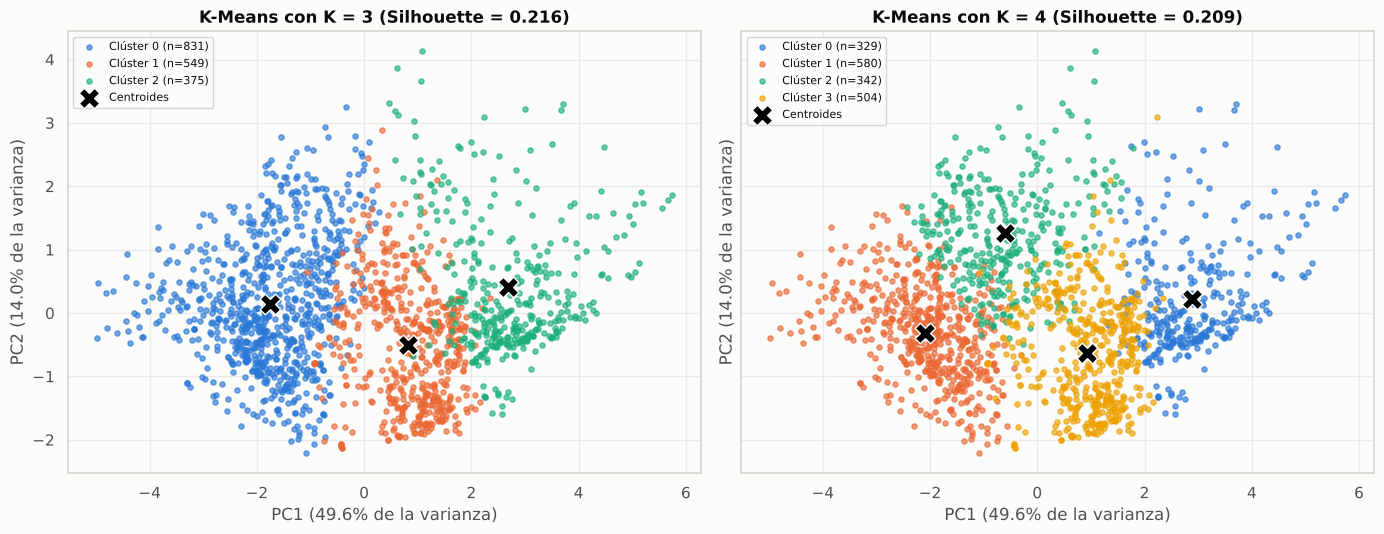

In [3]:
# Mismo PCA de la Actividad 2: dos componentes, ajustado solo con entrenamiento y sin la etiqueta
pca = PCA(n_components=2, random_state=SEMILLA)
componentes_train = pd.DataFrame(pca.fit_transform(X_train_escalado), columns=["PC1", "PC2"], index=X_train_escalado.index)
varianza_pc1, varianza_pc2 = pca.explained_variance_ratio_ * 100
print(f"Varianza explicada: PC1 {varianza_pc1:.2f}%, PC2 {varianza_pc2:.2f}%, acumulada {varianza_pc1 + varianza_pc2:.2f}%")

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for eje, k in zip(ejes, (3, 4)):
    etiquetas = resultados[k]["etiquetas"]
    for c in range(k):
        viviendas_grupo = componentes_train[etiquetas == c]
        eje.scatter(viviendas_grupo["PC1"], viviendas_grupo["PC2"], s=14, alpha=0.65, color=PALETA[c],
                    label=f"Clúster {c} (n={len(viviendas_grupo)})")
    centros = pd.DataFrame(resultados[k]["modelo"].cluster_centers_, columns=X_train_escalado.columns)
    centros_pc = pca.transform(centros)
    eje.scatter(centros_pc[:, 0], centros_pc[:, 1], marker="X", s=220, c="black", edgecolor="white", label="Centroides")
    eje.set_title(f"K-Means con K = {k} (Silhouette = {resultados[k]['silhouette']:.3f})")
    eje.set_xlabel(f"PC1 ({varianza_pc1:.1f}% de la varianza)")
    eje.set_ylabel(f"PC2 ({varianza_pc2:.1f}% de la varianza)")
    eje.legend(loc="upper left", fontsize=8)
plt.tight_layout()
guardar_figura("07_kmeans_k3_k4")
plt.show()

## 4. Perfil de los grupos

Para interpretar los grupos se utilizan sus **centroides**, que corresponden al promedio de cada variable dentro del grupo. Como K-Means trabajó con datos escalados, los centroides están en **unidades estandarizadas** y se leen así:

* **Valor positivo:** el grupo está sobre el promedio de entrenamiento en esa variable. Por ejemplo, 1,0 indica una desviación estándar por encima.
* **Valor negativo:** el grupo está bajo el promedio.
* **Valor cercano a 0:** el grupo se ubica en torno al promedio.

En las tablas, el rojo indica valores sobre el promedio y el azul valores bajo él. La columna `pct_precio_alto` muestra qué porcentaje de las viviendas del grupo se vendió sobre la mediana de precio. Se calcula **después** de formar los grupos y solo para interpretarlos, ya que K-Means no utilizó la etiqueta.

In [4]:
for k in (3, 4):
    etiquetas = resultados[k]["etiquetas"]
    perfil = pd.DataFrame(resultados[k]["modelo"].cluster_centers_, columns=X_train_escalado.columns.tolist())
    perfil["viviendas"] = np.bincount(etiquetas)
    perfil["pct_precio_alto"] = (y_train.groupby(etiquetas).mean().values * 100).round(0)
    perfil.index.name = f"Clúster (K = {k})"

    # Colores para leer los centroides: rojo sobre el promedio, azul bajo el promedio
    display(perfil.style
            .background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5, subset=X_train_escalado.columns.tolist())
            .format("{:.2f}", subset=X_train_escalado.columns.tolist())
            .format("{:.0f}%", subset=["pct_precio_alto"]))

,Overall Qual,Gr Liv Area,Garage Cars,Year Built,Full Bath,Total Bsmt SF,Year Remod/Add,Fireplaces,viviendas,pct_precio_alto
Clúster (K = 3),,,,,,,,,,
0,-0.70,-0.59,-0.65,-0.72,-0.81,-0.45,-0.64,-0.32,831,11%
1,0.23,0.15,0.28,0.55,0.71,-0.06,0.47,-0.14,549,75%
2,1.21,1.08,1.02,0.78,0.75,1.09,0.74,0.93,375,100%


,Overall Qual,Gr Liv Area,Garage Cars,Year Built,Full Bath,Total Bsmt SF,Year Remod/Add,Fireplaces,viviendas,pct_precio_alto
Clúster (K = 4),,,,,,,,,,
0,1.33,1.08,1.11,0.92,0.80,1.20,0.86,0.80,329,100%
1,-0.87,-0.80,-0.79,-0.67,-0.83,-0.55,-0.58,-0.84,580,3%
2,-0.23,0.08,-0.16,-0.71,-0.50,-0.12,-0.67,0.96,342,42%
3,0.28,0.17,0.30,0.65,0.77,-0.07,0.56,-0.20,504,77%


**Interpretación de los perfiles**

Con **K = 3**, los grupos siguen el mismo eje general que resume PC1, ya que en cada grupo casi todas las variables tienen el mismo signo.

| Clúster | Perfil | Viviendas | Sobre la mediana |
|---|---|---|---|
| 0 | **Básicas y antiguas.** Todas las variables bajo el promedio, en especial baños (−0,81), año de construcción (−0,72) y calidad (−0,70) | 831 | 11% |
| 1 | **Intermedias y modernas.** Calidad y tamaño cercanos al promedio, pero construcción y remodelación más recientes (0,55 y 0,47) y más baños (0,71) | 549 | 75% |
| 2 | **Premium.** Todas las variables sobre el promedio, con calidad (1,21), sótano (1,09) y superficie habitable (1,08) como las más altas | 375 | 100% |

Con **K = 4**, los clústeres premium e intermedio se mantienen con perfiles muy parecidos, y el grupo de viviendas básicas se divide en dos según la presencia de chimenea.

| Clúster | Perfil | Viviendas | Sobre la mediana |
|---|---|---|---|
| 0 | **Premium.** Todas las variables sobre el promedio, con calidad en 1,33 | 329 | 100% |
| 3 | **Intermedias y modernas.** Construcción reciente (0,65) y más baños (0,77), con calidad y tamaño cercanos al promedio | 504 | 77% |
| 2 | **Antiguas con chimenea.** Construidas y remodeladas hace más tiempo (−0,71 y −0,67), pero con chimenea (0,96) y superficie habitable en torno al promedio (0,08) | 342 | 42% |
| 1 | **Pequeñas y sencillas.** Las más bajas en casi todas las variables, incluida la chimenea (−0,84) | 580 | 3% |

El clúster 2 de K = 4 coincide con la dirección de PC2 descrita en la sección 4.3, que contrapone a las viviendas antiguas con chimenea frente a las más recientes. Además, aunque K-Means no utilizó el precio, la proporción de viviendas caras aumenta de forma ordenada desde los grupos más sencillos hasta los premium. Esto indica que los segmentos encontrados reflejan diferencias reales en el valor de las viviendas.

## Preguntas

**¿Qué cambia al pasar de tres a cuatro clústeres?**

Con K = 3 los grupos siguen un gradiente de tamaño, antigüedad y calidad: viviendas pequeñas, antiguas y sencillas (831 casos, 11% sobre la mediana de precio), viviendas intermedias (549 casos, 75%) y viviendas grandes, nuevas y de buena calidad (375 casos, 100%).

Al pasar a K = 4, el grupo de viviendas grandes casi se mantiene (329 casos, 100% sobre la mediana), mientras que el grupo de viviendas pequeñas y antiguas se divide en dos: uno de 580 casos sin chimenea, prácticamente todo bajo la mediana (3% sobre ella), y uno nuevo de 342 casos con chimenea, antiguo y de calidad media, con una mezcla de precios (42% sobre la mediana). La inercia baja (de 7.968 a 7.089), pero esto ocurre siempre al aumentar K y no indica por sí solo una mejor solución.

**¿Cuál de las dos soluciones obtuvo un mejor coeficiente Silhouette?**

K = 3, con 0,216 frente a 0,209 de K = 4. La diferencia es muy pequeña y ambos valores son bajos, lo que indica grupos poco separados que se tocan en los bordes, algo esperable en datos de viviendas, que forman un continuo. Una buena apariencia en el plano PC1 y PC2 no demuestra por sí sola que el agrupamiento sea de buena calidad.

**Expliquen brevemente cómo forma los grupos K-Means.**

K-Means elige K centroides iniciales y repite dos pasos: (1) asigna cada vivienda al centroide más cercano según la distancia euclidiana y (2) recalcula cada centroide como la media de las viviendas asignadas. El proceso termina cuando las asignaciones dejan de cambiar, buscando minimizar la suma de distancias al cuadrado dentro de cada grupo (inercia). Por eso depende de la escala de las variables, que aquí ya fueron estandarizadas, y tiende a formar grupos compactos de forma aproximadamente esférica. No utiliza la etiqueta `precio_alto`.